# P0：RQ1 机场延误净变化（原始描述）

研究问题：哪些机场的同机相邻航段衔接平均吸收或放大延误？本阶段先报告开发期原始汇总；共同支持标准化、日期块区间和阈值敏感性留待 P5。

In [1]:
ROOT = __import__('pathlib').Path.cwd()
RUN_DIR = ROOT / 'experiments/runs/R0021'

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

if "ROOT" not in globals():
    ROOT = Path.cwd()
    while not (ROOT / "scripts/build_features.py").exists():
        if ROOT.parent == ROOT:
            raise RuntimeError("请在 Airline-delay 仓库中运行 Notebook")
        ROOT = ROOT.parent
if "RUN_DIR" not in globals():
    candidates = [p for p in (ROOT / "experiments/runs").glob("R*")
                  if (p / "metrics.csv").exists() and (p / "eda_summary.json").exists()
                  and (p / "rq1_summary.json").exists()]
    if not candidates:
        raise RuntimeError("请先运行 P0 开发分析，或手动设置 RUN_DIR")
    RUN_DIR = max(candidates, key=lambda p: int(p.name[1:]))
TABLES = RUN_DIR / "tables"
FIGURES = RUN_DIR / "figures"
def table(name):
    return pd.read_csv(TABLES / name)
def figure(name):
    display(Image(filename=str(FIGURES / name)))
def receipt(name):
    return json.loads((RUN_DIR / name).read_text(encoding="utf-8"))
display(Markdown(f"**归档运行：{RUN_DIR.name}**。本 Notebook 读取该轮表格与图，不重新拟合模型。"))

**归档运行：R0021**。本 Notebook 读取该轮表格与图，不重新拟合模型。

## 1. 主样本与三个不同的量

主样本来自有效衔接，要求上游非负到达延误至少 15 分钟、计划非隔夜。RQ1 允许实际地面时间为 0；不套用 RQ2 的严格预测早于出发条件。开发期先按上游实际到达 UTC 4–7 月筛选，再分析目标。

\[\Delta_i = D_{down,i}^{dep} - D_{up,i}^{arr}\]

**每次平均净变化**的单位是分钟/次衔接；**累计增加** \(S_+=\sum \max(\Delta_i,0)\)、**累计减少** \(S_-=\sum\max(-\Delta_i,0)\) 和 **累计净变化** \(S_{net}=\sum\Delta_i=S_+-S_-\) 的单位是样本总分钟。累计量受样本量影响，不能直接当作机场表现。

In [3]:
summary = receipt("rq1_summary.json")
display(pd.DataFrame(list(summary["counts"].items()), columns=["顺序样本流", "数量"]))
display(pd.DataFrame([{k: v for k, v in summary.items() if k not in ["counts", "interpretation"]}]))
assert summary["delta_identity_checked"]

,顺序样本流,数量
0,input_accepted_connections,2821852
1,outside_prediction_utc_scope,560077
2,scoped_accepted_connections,2261775
3,invalid_delay,0
4,invalid_actual_ground,0
5,upstream_below_15,1731755
6,scheduled_overnight,150345
7,main_connections,379675
8,main_ground_zero_n,0


,development_only,connection_path,sample_rule,airports,mean_delta,s_plus,s_minus,s_net,delta_identity_checked,standardized,uncertainty_intervals
0,True,processed/D0003/flight_connections.csv.gz,"accepted, upstream delay >=15 min, non-overnig...",349,-7.466249,4071355.0,6906103.0,-2834748.0,True,False,False


## 2. 机场原始均值、分布与支持

按样本量选择最大的 20 个机场展示；图内顺序不构成标准化排名。表中 mean/median/p10/p90、减少/增加/不变比例均使用同一主样本。完整机场表归档于 tables/rq1_airport_raw.csv。

,airport_id,airport_code,n,mean_delta,median_delta,p10_delta,p90_delta,reduction_share,amplification_share,unchanged_share,s_plus,s_minus,s_net,upstream_mean,downstream_mean,scheduled_turnaround_mean,supported_months
0,13930,ORD,22218,-23.556396,-16.0,-77.0,18.0,0.782519,0.206499,0.010982,187691.0,711067.0,-523376.0,71.940724,48.384328,100.535377,4
1,11292,DEN,18867,-14.022738,-8.0,-52.0,22.0,0.632639,0.347697,0.019664,159464.0,424031.0,-264567.0,61.199555,47.176817,87.569990,4
2,11298,DFW,18127,-22.846362,-14.0,-90.0,30.0,0.710156,0.276328,0.013516,198911.0,613047.0,-414136.0,73.484691,50.638330,113.499917,4
3,14771,SFO,18029,-15.069943,-14.0,-45.0,12.0,0.768429,0.215597,0.015974,104049.0,375745.0,-271696.0,56.069555,40.999612,88.444950,4
4,10397,ATL,15565,-15.525859,-8.0,-69.0,28.0,0.644523,0.337231,0.018246,167677.0,409337.0,-241660.0,66.547767,51.021908,117.296049,4
5,14107,PHX,10537,-12.895321,-6.0,-56.0,20.0,0.610800,0.368511,0.020689,87681.0,223559.0,-135878.0,56.374015,43.478694,86.565816,4
6,12889,LAS,10533,-3.156461,-1.0,-33.0,24.0,0.509541,0.466534,0.023925,101720.0,134967.0,-33247.0,53.142884,49.986424,74.905250,4
7,12892,LAX,9512,-14.470984,-10.0,-52.0,18.0,0.692494,0.291737,0.015770,68273.0,205921.0,-137648.0,53.886144,39.415160,109.734546,4
8,11057,CLT,8882,-21.392817,-13.0,-84.0,28.0,0.702319,0.284508,0.013173,97351.0,287362.0,-190011.0,68.719883,47.327066,113.563161,4
9,13204,MCO,8800,-3.538409,-2.0,-38.0,28.0,0.525795,0.449432,0.024773,105802.0,136940.0,-31138.0,58.724886,55.186477,101.510682,4


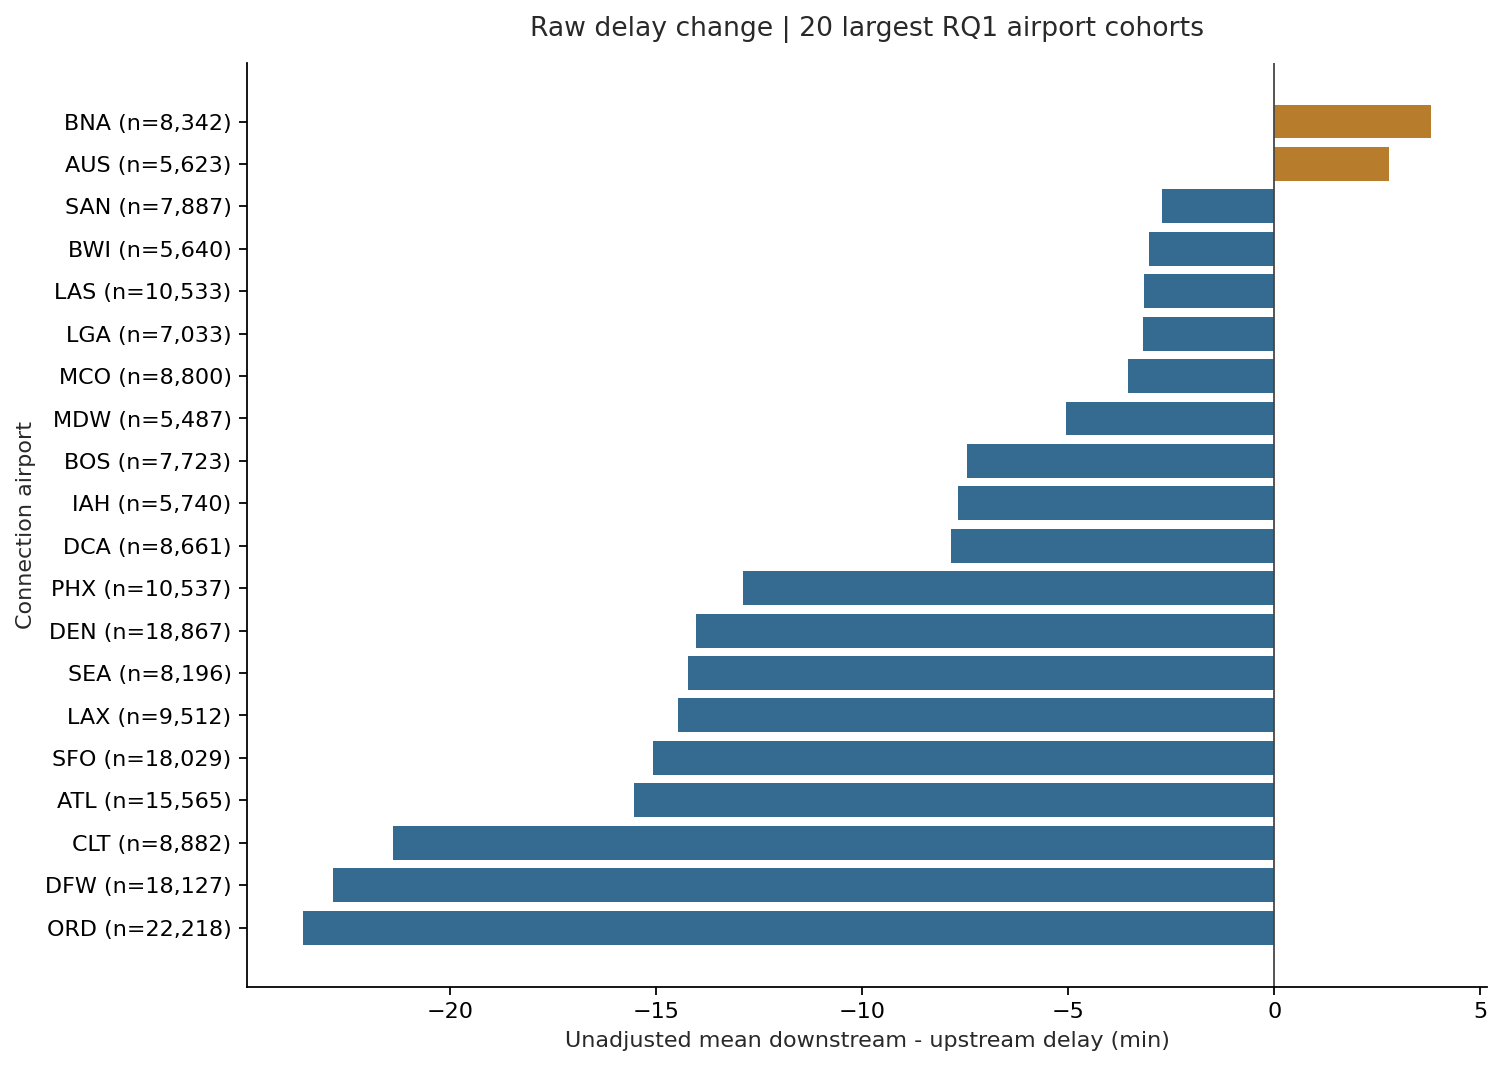

In [4]:
raw = table("rq1_airport_raw.csv")
display(raw.head(20))
figure("rq1_raw_airport_mean.png")

## 3. 累计增加、累计减少与净值

较大机场的累计分钟可能很高，即使其每次平均净变化较小。必须将累计量与样本量及每次平均量一起阅读。逐连接与逐机场均验证 Snet = S+ − S−，避免正负变化混算。

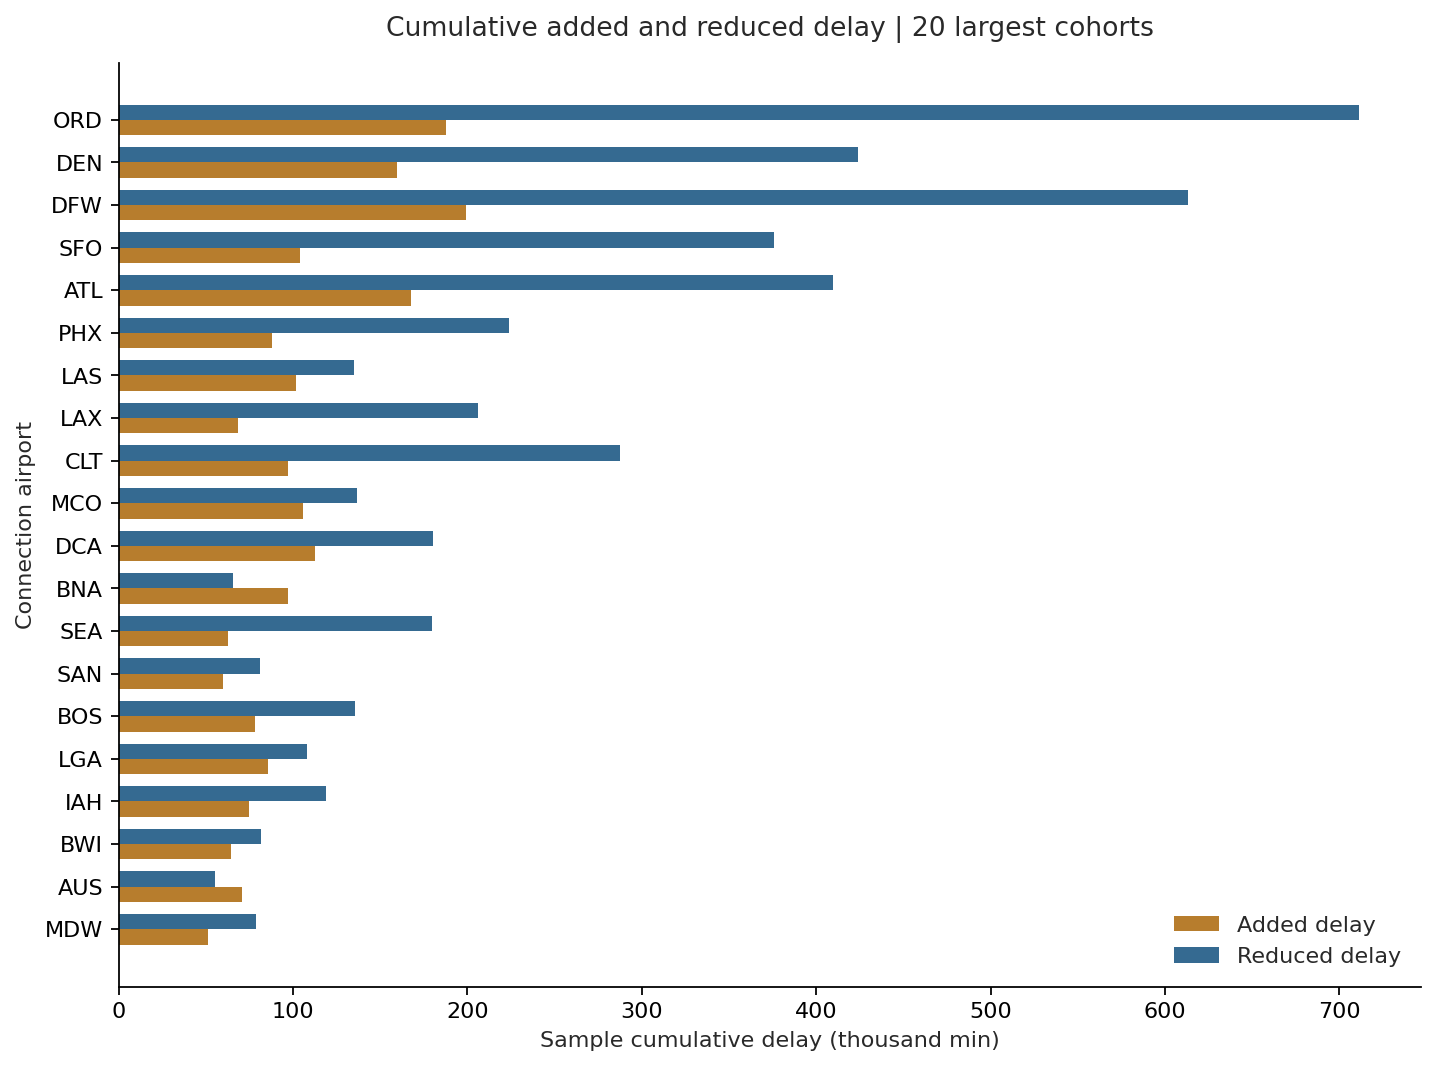

,airport_id,airport_code,n,mean_delta,s_plus,s_minus,s_net
0,13930,ORD,22218,-23.556396,187691.0,711067.0,-523376.0
1,11292,DEN,18867,-14.022738,159464.0,424031.0,-264567.0
2,11298,DFW,18127,-22.846362,198911.0,613047.0,-414136.0
3,14771,SFO,18029,-15.069943,104049.0,375745.0,-271696.0
4,10397,ATL,15565,-15.525859,167677.0,409337.0,-241660.0
5,14107,PHX,10537,-12.895321,87681.0,223559.0,-135878.0
6,12889,LAS,10533,-3.156461,101720.0,134967.0,-33247.0
7,12892,LAX,9512,-14.470984,68273.0,205921.0,-137648.0
8,11057,CLT,8882,-21.392817,97351.0,287362.0,-190011.0
9,13204,MCO,8800,-3.538409,105802.0,136940.0,-31138.0


In [5]:
figure("rq1_cumulative_delay.png")
display(raw[["airport_id", "airport_code", "n", "mean_delta", "s_plus", "s_minus", "s_net"]].head(20))

## 4. 分月支持及上游延误 × 计划周转

逐月表帮助识别月份组成变化。热图分别列计数与平均净变化：低支持格不足以支持稳定结论。没有正式最低周转时间，本项目只使用计划周转，不把它直接命名为可吸收缓冲。

,connections
month_utc,
2026-04,79257
2026-05,86498
2026-06,101722
2026-07,112198


,month_utc,airport_id,airport_code,n,mean_delta,median_delta,p10_delta,p90_delta,reduction_share,amplification_share,unchanged_share,s_plus,s_minus,s_net,upstream_mean,downstream_mean,scheduled_turnaround_mean,supported_months
0,2026-04,10135,ABE,36,19.972222,-3.5,-23.0,13.5,0.638889,0.333333,0.027778,1137.0,418.0,719.0,54.583333,74.555556,102.805556,1
1,2026-04,10136,ABI,24,-2.916667,-4.5,-33.8,36.5,0.708333,0.291667,0.000000,226.0,296.0,-70.0,71.250000,68.333333,45.875000,1
2,2026-04,10140,ABQ,244,1.872951,-3.0,-23.0,15.0,0.590164,0.352459,0.057377,2576.0,2119.0,457.0,45.536885,47.409836,66.717213,1
3,2026-04,10141,ABR,4,-9.250000,-9.5,-14.7,-3.6,1.000000,0.000000,0.000000,0.0,37.0,-37.0,72.000000,62.750000,36.000000,1
4,2026-04,10155,ACT,5,-8.000000,-7.0,-12.2,-4.8,1.000000,0.000000,0.000000,0.0,40.0,-40.0,63.800000,55.800000,30.000000,1
5,2026-04,10157,ACV,32,-0.156250,-2.0,-18.8,19.7,0.656250,0.343750,0.000000,185.0,190.0,-5.0,61.843750,61.687500,42.875000,1
6,2026-04,10158,ACY,41,-23.487805,-11.0,-86.0,9.0,0.780488,0.219512,0.000000,109.0,1072.0,-963.0,62.682927,39.195122,160.365854,1
7,2026-04,10165,ADK,2,7.000000,7.0,0.6,13.4,0.500000,0.500000,0.000000,15.0,1.0,14.0,79.500000,86.500000,56.000000,1
8,2026-04,10170,ADQ,3,-1.666667,-1.0,-5.8,2.2,0.666667,0.333333,0.000000,3.0,8.0,-5.0,35.333333,33.666667,52.000000,1
9,2026-04,10185,AEX,5,11.400000,2.0,-2.6,35.4,0.400000,0.600000,0.000000,62.0,5.0,57.0,61.400000,72.800000,30.000000,1


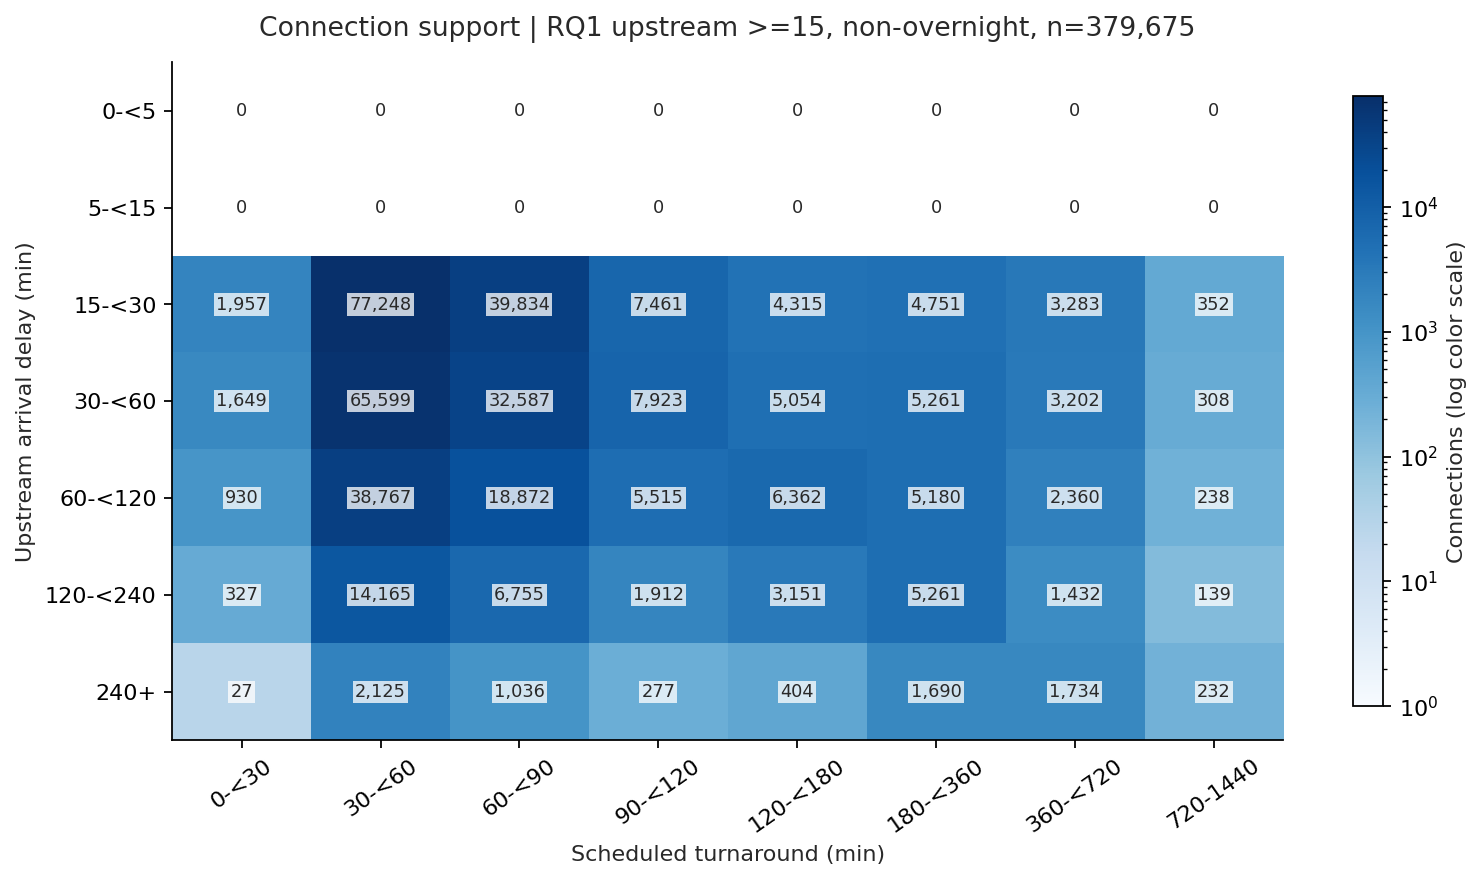

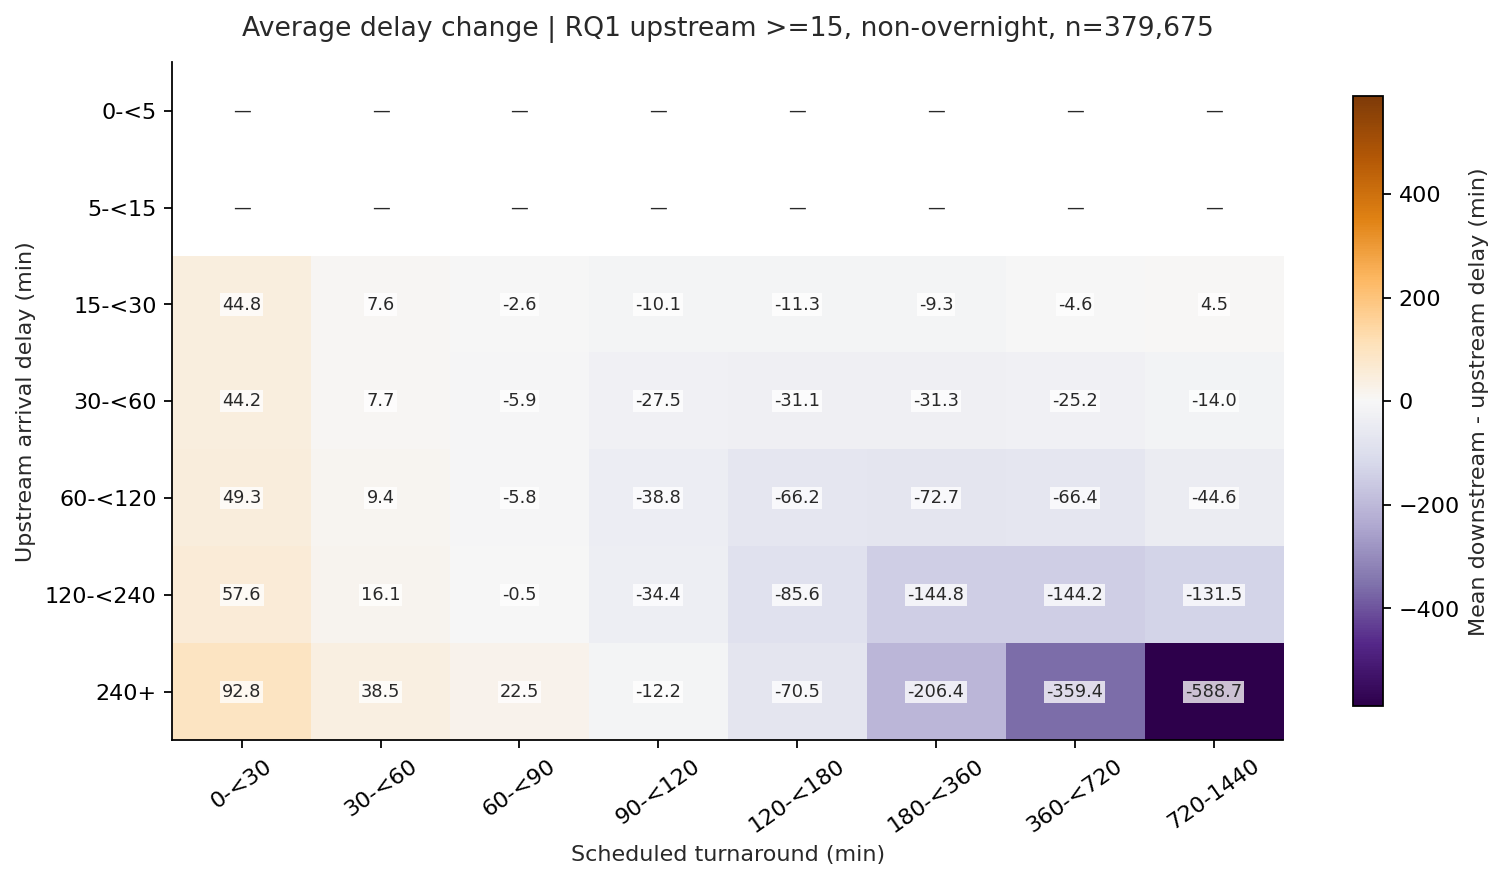

In [6]:
monthly = table("rq1_airport_monthly.csv")
display(monthly.groupby("month_utc")["n"].sum().rename("connections").to_frame())
display(monthly.head(20))
figure("rq1_turnaround_count.png")
figure("rq1_turnaround_mean_delta.png")

## 5. 当前可以与尚不能得出的结论

负 Δ 表示这次衔接保留的下游延误少于上游晚到；下游仍可能延误。当前机场差异尚未按共同上游延误和计划周转分布标准化，也没有抽样不确定性区间，因此只能描述本样本的原始表现，不能解释为机场因果责任或正式优劣排名。